# Non-contextual $m$-set semi-bandit

A toy comparison of `SquareCB.comb` under a linear and two boosted decision-tree oracles, `SquareCB.lin`, epsilon-greedy, VCEE, and LinUCB using the implementations in `src/algorithms`.

There are $K$ Bernoulli arms with fixed means $\mu\in[0,1]^K$. At round $t$, a learner selects any subset $A_t\subseteq[K]$ of size $m$ and receives

$$r_t(A_t)=\sum_{i\in A_t}Y_{t,i},\qquad Y_{t,i}\sim\operatorname{Bernoulli}(\mu_i).$$

Every method sees the same one-hot arm features $\phi_i=e_i\in\mathbb R^K$; there is no varying context. Performance is measured by cumulative pseudo-regret

$$R_T=\sum_{t=1}^T\left(\sum_{i\in A^*}\mu_i-\sum_{i\in A_t}\mu_i\right),$$

where $A^*$ contains the $m$ arms with largest means. This removes reward noise from the metric while leaving the observations stochastic.


In [1]:
import contextlib
import io
import math
import os
import sys
import warnings
from dataclasses import dataclass

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from sklearn.linear_model import LinearRegression
from IPython.display import display

SRC = os.path.join(os.getcwd(), "src")
assert os.path.isdir(SRC), "Run this notebook from the repository root."
if SRC not in sys.path:
    sys.path.insert(0, SRC)

from Context import Context
from algorithms import EpsGreedy, LinUCB, MiniMonster, SquareCB, SquareCBLin

plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False,
                     "axes.spines.right": False})


@dataclass(frozen=True)
class ExperimentConfig:
    means: tuple = (0.90, 0.82, 0.74, 0.52, 0.48, 0.44, 0.40, 0.36, 0.32, 0.28)
    m_values: tuple = tuple(range(1, 11))
    gamma_exponents: tuple = tuple(np.arange(-3.0, 3.01, 0.5))
    T: int = 1_000
    n_seeds: int = 8
    seed0: int = 2026
    n_jobs: int = -1
    output_dir: str = "results/noncontextual_mset"


CFG = ExperimentConfig()
CFG


ExperimentConfig(means=(0.9, 0.82, 0.74, 0.52, 0.48, 0.44, 0.4, 0.36, 0.32, 0.28), m_values=(1, 2, 3, 4, 5, 6, 7, 8, 9, 10), gamma_exponents=(np.float64(-3.0), np.float64(-2.5), np.float64(-2.0), np.float64(-1.5), np.float64(-1.0), np.float64(-0.5), np.float64(0.0), np.float64(0.5), np.float64(1.0), np.float64(1.5), np.float64(2.0), np.float64(2.5), np.float64(3.0)), T=1000, n_seeds=8, seed0=2026, n_jobs=-1, output_dir='results/noncontextual_mset')

## Environment

`MSetEnv` implements the small simulator interface consumed by the repository algorithms. Its single `Context` contains the fixed $K\times K$ identity matrix. Thus a linear score can assign an independent value to every arm, and the best action under any score vector is simply its top-$m$ coordinates.


In [2]:
class MSetEnv:
    """Stationary Bernoulli semi-bandit with all size-m subsets feasible."""

    def __init__(self, means, m, seed):
        self.means = np.asarray(means, dtype=float)
        self.K = self.d = self.means.size
        self.L = int(m)
        if not (1 <= self.L <= self.K):
            raise ValueError("m must lie in {1, ..., K}.")
        if np.any((self.means < 0) | (self.means > 1)):
            raise ValueError("Bernoulli means must lie in [0, 1].")

        self.N = math.comb(self.K, self.L)
        self.weight = np.ones(self.L)
        self.features = np.eye(self.K)
        self.context = Context("stationary", self.features, self.K, self.L)
        self.opt_action = np.argsort(self.means)[-self.L:]
        self.opt_value = float(self.means[self.opt_action].sum())
        self.rng = np.random.default_rng(seed)
        self.curr_r = None

    def get_new_context(self):
        self.curr_r = self.rng.binomial(1, self.means).astype(float)
        return self.context

    def get_slate_reward(self, action):
        return float(self.curr_r[np.asarray(action, dtype=int)].sum())

    def get_base_rewards(self, action):
        return self.curr_r[np.asarray(action, dtype=int)]

    def get_best_reward(self):
        return self.opt_value

    def check_action(self, action):
        action = np.asarray(action, dtype=int)
        if (action.shape != (self.L,) or np.unique(action).size != self.L
                or np.any((action < 0) | (action >= self.K))):
            raise ValueError(f"Invalid size-{self.L} subset: {action}")


env = MSetEnv(CFG.means, CFG.m_values[0], CFG.seed0)
instance = pd.DataFrame({"arm": np.arange(env.K), "mean": env.means})
configurations = pd.DataFrame({
    "m": CFG.m_values,
    "number of actions": [math.comb(env.K, m) for m in CFG.m_values],
    "optimal expected reward": [np.sort(env.means)[-m:].sum() for m in CFG.m_values],
})
print(f"K={env.K} arms; sweeping m={CFG.m_values[0]}, ..., {CFG.m_values[-1]}")
display(instance.T)
configurations


K=10 arms; sweeping m=1, ..., 10


,0,1,2,3,4,5,6,7,8,9
arm,0.0,1.00,2.00,3.00,4.00,5.00,6.0,7.00,8.00,9.00
mean,0.9,0.82,0.74,0.52,0.48,0.44,0.4,0.36,0.32,0.28


,m,number of actions,optimal expected reward
0,1,10,0.90
1,2,45,1.72
2,3,120,2.46
3,4,210,2.98
4,5,252,3.46
5,6,210,3.90
6,7,120,4.30
7,8,45,4.66
8,9,10,4.98
9,10,1,5.26


## Algorithms

All action rules are already top-$m$ rules in the stock classes, so the experiment uses them without subclassing. The three `SquareCB.comb` rows share an algorithm and differ only in the reward oracle `model_type` hands to `learning_oracles.online_oracles.make_oracle`.

| label | implementation reused | reward oracle | feedback used for learning |
|---|---|---|---|
| `SquareCB.comb` | `algorithms.SquareCB` | linear head, one SGD step per round | the $m$ observed arm rewards |
| `SquareCB.comb (gb5)` | `algorithms.SquareCB` | depth-5 `GradientBoostingRegressor`, refit on a doubling schedule | the $m$ observed arm rewards |
| `SquareCB.comb (xgb5)` | `algorithms.SquareCB` | depth-5 XGBoost, one tree appended every 10 rounds | the $m$ observed arm rewards |
| `SquareCB.lin` | `algorithms.SquareCBLin` | linear head, one SGD step per round | aggregate set reward only |
| `Epsilon-greedy` | `algorithms.EpsGreedy` | `LinearRegression`, batch refit | the $m$ observed arm rewards |
| `VCEE` | `algorithms.MiniMonster` | `LinearRegression`, batch refit | importance-weighted semi-bandit feedback |
| `LinUCB` | `algorithms.LinUCB` | ridge, closed form | the $m$ observed arm rewards |

### The tree oracles

`gb5` and `xgb5` are the same depth-5 boosted-tree oracles the MSLR and Yahoo campaigns run (`online_gb_oracle.OnlineGBOracle`, `online_xgb_oracle.OnlineXGBOracle`). IGW consumes only a pointwise estimate of $\mathbb E[y\mid\phi]$, so swapping the linear head for a tree ensemble changes the estimator and leaves the algorithm untouched. The two differ in update discipline rather than model class: `gb5` refits a fresh 100-tree ensemble on the whole replay buffer at rounds $\text{burn\_in}+2^k$, while `xgb5` appends one tree to a running booster every 10 rounds over a 2000-row FIFO window.

Depth 5 rather than 2 because the features are one-hot: a tree can only separate arms by splitting on coordinates, and a single depth-2 tree emits just 4 distinct values against $K=10$ arms, so it has to lean on the ensemble to tell them apart. Depth 5 gives 32 leaves and can isolate every arm within one tree.

One default is overridden. `OnlineGBOracle` ships `burn_in=200`, sized for the repository's $T=30{,}000$ runs; until it elapses the oracle predicts zeros and IGW samples uniformly. At $T=1000$ that would spend a fifth of the horizon exploring blind — measured at $m=3$, about 170 of `gb5`'s roughly 300 total pseudo-regret is accrued before round 200. The notebook sets `burn_in=50`, in the same range as the XGBoost oracle's 50-row `warmup`. Everything else is stock.

Note what this instance is: one-hot features make the reward exactly linear, so `SquareCB.comb` is already correctly specified. The tree rows measure what a nonparametric oracle costs when the linear model is *right*, which is close to the worst case for them — not a setting where trees have anything to exploit.

`SquareCB.lin` is intentionally evaluated under its native bandit-feedback update, and keeps the linear oracle its analysis assumes. Feature normalization is disabled for it so that the super-action feature remains exactly $\sum_{i\in A}e_i$. The seven-algorithm comparison uses `gamma_multiplier=1`; the sensitivity experiment below sweeps this parameter for all four SquareCB variants. Other displayed hyperparameters are modest illustrative defaults, not tuned on this instance.


In [3]:
def batch_linear_oracle():
    return LinearRegression()


def make_algorithm(name, env, seed, gamma_multiplier=1.0):
    if name == "SquareCB.comb":
        return SquareCB(env, classification=False), {
            "model_type": "linear",
            "gamma_multiplier": float(gamma_multiplier), "seed": seed}
    if name == "SquareCB.comb (gb5)":
        # Same algorithm as SquareCB.comb; only the oracle changes. The stock
        # burn_in=200 is sized for the T=30,000 campaigns and would leave this
        # T=1,000 run sampling uniformly for its first fifth.
        return SquareCB(env, classification=False), {
            "model_type": "gb5", "burn_in": 50,
            "gamma_multiplier": float(gamma_multiplier), "seed": seed}
    if name == "SquareCB.comb (xgb5)":
        return SquareCB(env, classification=False), {
            "model_type": "xgb5",
            "gamma_multiplier": float(gamma_multiplier), "seed": seed}
    if name == "SquareCB.lin":
        return SquareCBLin(env, classification=False), {
            "model_type": "linear",
            "gamma_multiplier": float(gamma_multiplier),
            "normalize_features": False, "seed": seed}
    if name == "Epsilon-greedy":
        return EpsGreedy(env, learning_alg=batch_linear_oracle,
                         classification=False), {
            "eps": 0.05, "train_all": True, "weight": np.ones(env.L)}
    if name == "VCEE":
        return MiniMonster(env, learning_alg=batch_linear_oracle,
                           classification=False, lin_cache=True), {"mu": 1.0}
    if name == "LinUCB":
        return LinUCB(env), {"delta": 1.0, "schedule": 10}
    raise KeyError(name)


ALGORITHMS = ("SquareCB.comb", "SquareCB.comb (gb5)",
              "SquareCB.comb (xgb5)", "SquareCB.lin", "Epsilon-greedy",
              "VCEE", "LinUCB")
SQUARECB_ALGORITHMS = ("SquareCB.comb", "SquareCB.comb (gb5)",
                       "SquareCB.comb (xgb5)", "SquareCB.lin")
BASELINES = tuple(name for name in ALGORITHMS if name not in SQUARECB_ALGORITHMS)


def run_one(name, cfg, m, seed, gamma_multiplier=1.0):
    """Run the online protocol and return round-level diagnostics."""
    env = MSetEnv(cfg.means, m, seed)
    np.random.seed(seed)  # EpsGreedy, VCEE, and LinUCB use NumPy's legacy RNG.
    alg, params = make_algorithm(name, env, seed, gamma_multiplier)
    alg.verbose = False

    # EpsGreedy prints its refit schedule during init; keep the experiment output tidy.
    with contextlib.redirect_stdout(io.StringIO()):
        alg.init(cfg.T, params=params)

    regret = np.empty(cfg.T)
    reward = np.empty(cfg.T)
    optimal = np.empty(cfg.T, dtype=bool)
    opt_key = tuple(sorted(env.opt_action.tolist()))

    for t in range(cfg.T):
        context = env.get_new_context()
        action = np.asarray(alg.get_action(context), dtype=int)
        env.check_action(action)
        set_reward = env.get_slate_reward(action)
        arm_rewards = env.get_base_rewards(action)
        alg.update(context, action, arm_rewards, set_reward)

        regret[t] = env.opt_value - env.means[action].sum()
        reward[t] = set_reward
        optimal[t] = tuple(sorted(action.tolist())) == opt_key

    return {"cum_regret": np.cumsum(regret),
            "cum_reward": np.cumsum(reward),
            "optimal": optimal}


In [4]:
seeds = range(CFG.seed0, CFG.seed0 + CFG.n_seeds)
runs, gamma_runs = {}, {}
for m in CFG.m_values:
    # Baselines do not depend on gamma_multiplier; SquareCB does.
    jobs = ([(name, seed, None) for name in BASELINES for seed in seeds]
            + [(name, seed, exponent)
               for name in SQUARECB_ALGORITHMS
               for exponent in CFG.gamma_exponents for seed in seeds])
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore", message="A worker stopped while some jobs.*")
        completed = Parallel(n_jobs=CFG.n_jobs)(
            delayed(run_one)(name, CFG, m, seed,
                             1.0 if exponent is None else 2.0 ** exponent)
            for name, seed, exponent in jobs)
    runs[m] = {name: [] for name in ALGORITHMS}
    gamma_runs[m] = {name: {e: [] for e in CFG.gamma_exponents}
                     for name in SQUARECB_ALGORITHMS}
    for (name, _, exponent), result in zip(jobs, completed):
        if exponent is None:
            runs[m][name].append(result)
        else:
            gamma_runs[m][name][exponent].append(result)
    for name in SQUARECB_ALGORITHMS:
        runs[m][name] = gamma_runs[m][name][0.0]  # reference multiplier 2^0 = 1
    print(f"m={m:2d}: {len(BASELINES)} baselines + "
          f"{len(SQUARECB_ALGORITHMS)} SquareCB variants x "
          f"{len(CFG.gamma_exponents)} multipliers x {CFG.n_seeds} seeds")


m= 1: 3 baselines + 4 SquareCB variants x 13 multipliers x 8 seeds


m= 2: 3 baselines + 4 SquareCB variants x 13 multipliers x 8 seeds


m= 3: 3 baselines + 4 SquareCB variants x 13 multipliers x 8 seeds


m= 4: 3 baselines + 4 SquareCB variants x 13 multipliers x 8 seeds


m= 5: 3 baselines + 4 SquareCB variants x 13 multipliers x 8 seeds


m= 6: 3 baselines + 4 SquareCB variants x 13 multipliers x 8 seeds


m= 7: 3 baselines + 4 SquareCB variants x 13 multipliers x 8 seeds


m= 8: 3 baselines + 4 SquareCB variants x 13 multipliers x 8 seeds


m= 9: 3 baselines + 4 SquareCB variants x 13 multipliers x 8 seeds


m=10: 3 baselines + 4 SquareCB variants x 13 multipliers x 8 seeds


## Results

Each panel shows mean cumulative pseudo-regret for one set size at the reference `gamma_multiplier=1`; shaded bands are 95% normal confidence intervals. The notebook saves the combined grid, one full-size plot per configuration, and a final-regret summary to `CFG.output_dir`. The table reports mean final pseudo-regret; lower is better.

This section and the multiplier sweep below render the same layout — one full-size figure per $m$, then every $m$ together on a common scale — so that assembly is written once in `panel_figures` and each section supplies only a per-panel `draw` callback. The grid shape follows `CFG.m_values`, so changing the swept sizes needs no edit to the plotting code.


In [5]:
# Shared plotting helpers. Both result sections below draw the same shape,
# so only the per-panel curve is a callback; the figure assembly lives here.
K = len(CFG.means)
colors = {"SquareCB.comb": "#2a78d6", "SquareCB.comb (gb5)": "#00a2b3",
          "SquareCB.comb (xgb5)": "#0c2c6b", "SquareCB.lin": "#7a5af8",
          "Epsilon-greedy": "#e58b00", "VCEE": "#d94f70",
          "LinUCB": "#3a8f5b"}
# The SquareCB.comb rows are one algorithm under three oracles: they keep a
# common cool-blue family and separate by dash pattern.
dashes = {"SquareCB.comb (gb5)": "--", "SquareCB.comb (xgb5)": "-."}
styles = {name: dashes.get(name, "-") for name in ALGORITHMS}
steps = np.arange(1, CFG.T + 1)


def save_fig(fig, path, show=True):
    """Tight-layout, write at print resolution, then display or discard."""
    fig.tight_layout()
    fig.savefig(path, dpi=180, bbox_inches="tight")
    if show:
        plt.show()
    else:
        plt.close(fig)


def panel_figures(draw, *, outdir, per_m_name, grid_name, suptitle,
                  xlabel, ylabel, legend_ncol, annotate=None,
                  legend_y=1.01, suptitle_y=1.05):
    """Render one panel per set size at full size, then all of them as a grid.

    ``draw(ax, m, compact=False)`` paints a single panel and labels its own
    curves; ``compact`` drops the per-axis labels, which the grid sets once
    per edge instead. Each m first gets its own readable figure in ``outdir``,
    then they share one grid on a common scale with the legend lifted off the
    first panel. The grid shape follows ``CFG.m_values``.
    """
    os.makedirs(outdir, exist_ok=True)
    for m in CFG.m_values:
        fig, ax = plt.subplots(figsize=(8.2, 4.6))
        draw(ax, m)
        ax.legend(frameon=False, ncol=2)
        if annotate is not None:
            ax.text(0.01, 0.02, annotate, transform=ax.transAxes,
                    color="#555555")
        save_fig(fig, os.path.join(outdir, per_m_name.format(m=m)), show=False)

    ncols = min(5, len(CFG.m_values))
    nrows = math.ceil(len(CFG.m_values) / ncols)
    fig, axes = plt.subplots(nrows, ncols, sharex=True, sharey=True,
                             figsize=(3.6 * ncols, 3.5 * nrows), squeeze=False)
    for ax, m in zip(axes.flat, CFG.m_values):
        draw(ax, m, compact=True)
    for ax in axes.flat[len(CFG.m_values):]:
        ax.set_visible(False)
    for row in axes:
        row[0].set_ylabel(ylabel)
    for col in axes.T:
        shown = [ax for ax in col if ax.get_visible()]
        if shown:
            shown[-1].set_xlabel(xlabel)
    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=legend_ncol,
               frameon=False, bbox_to_anchor=(0.5, legend_y))
    fig.suptitle(suptitle, y=suptitle_y, fontsize=14)
    save_fig(fig, os.path.join(outdir, grid_name))


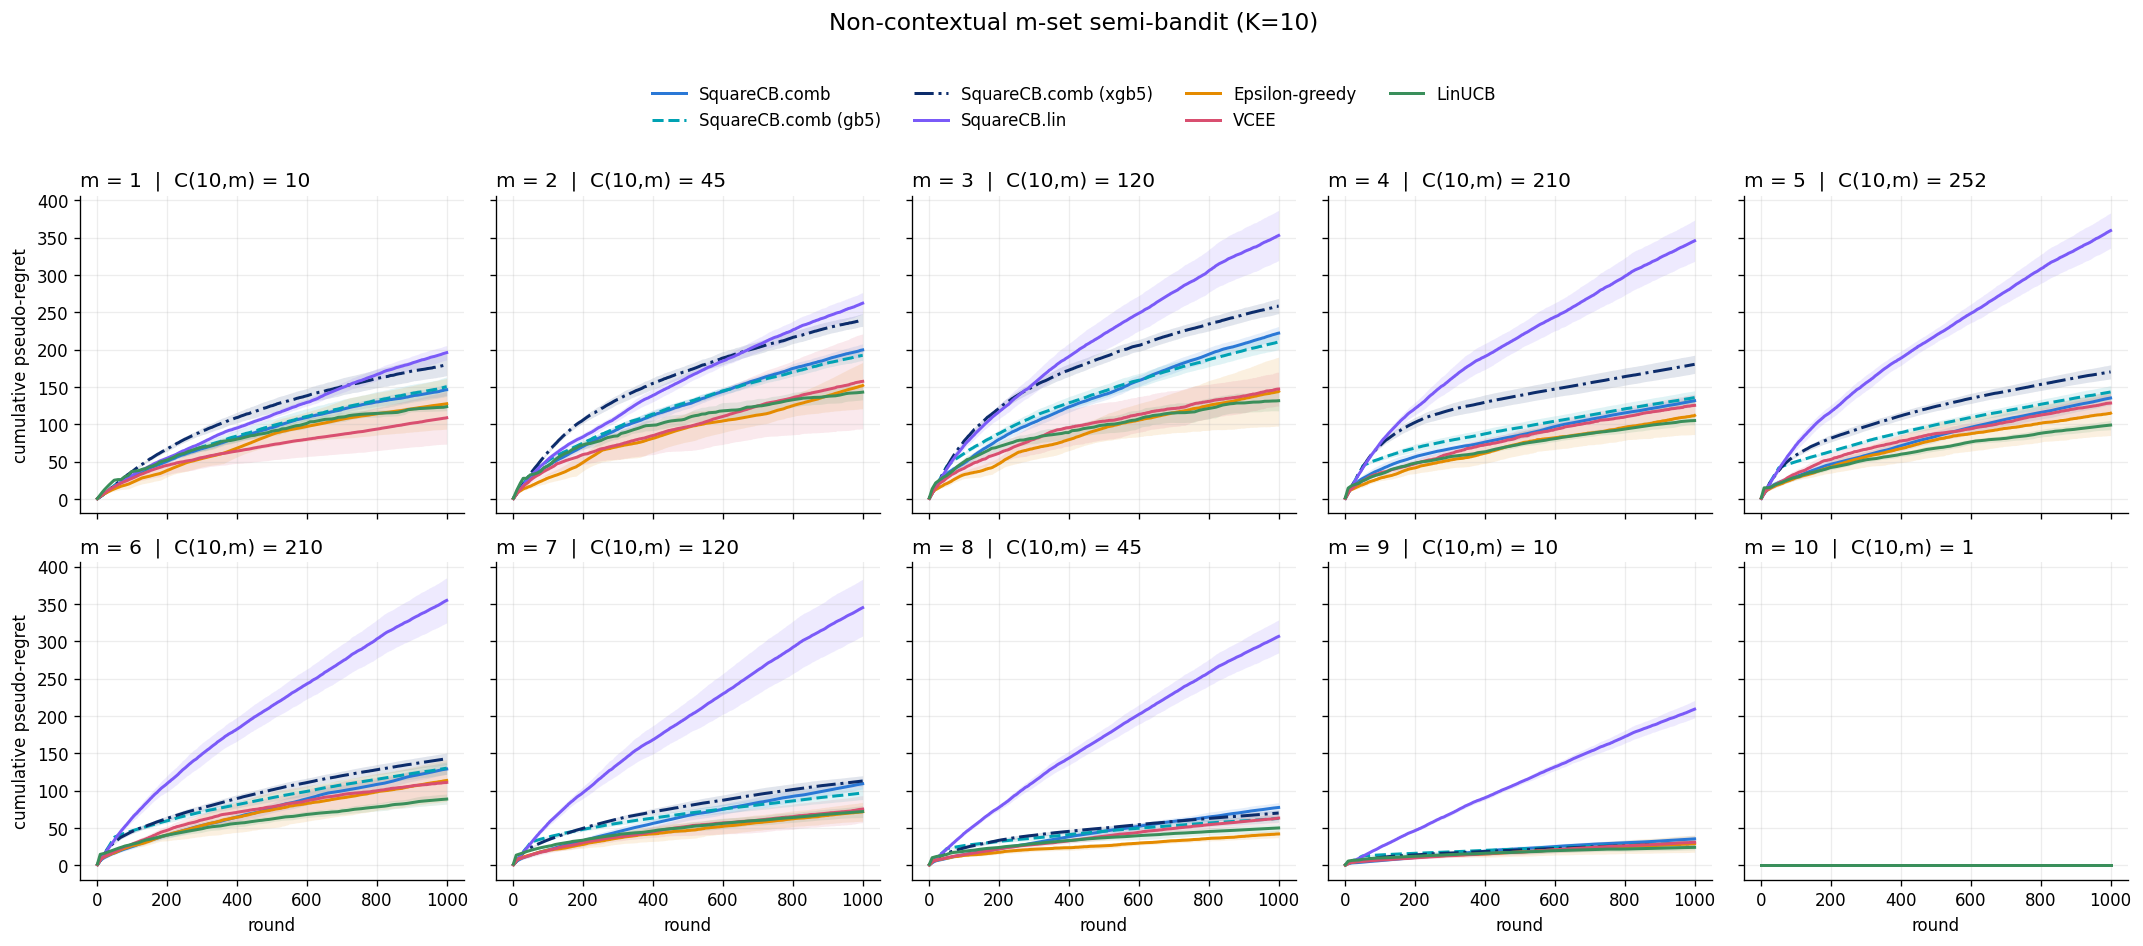

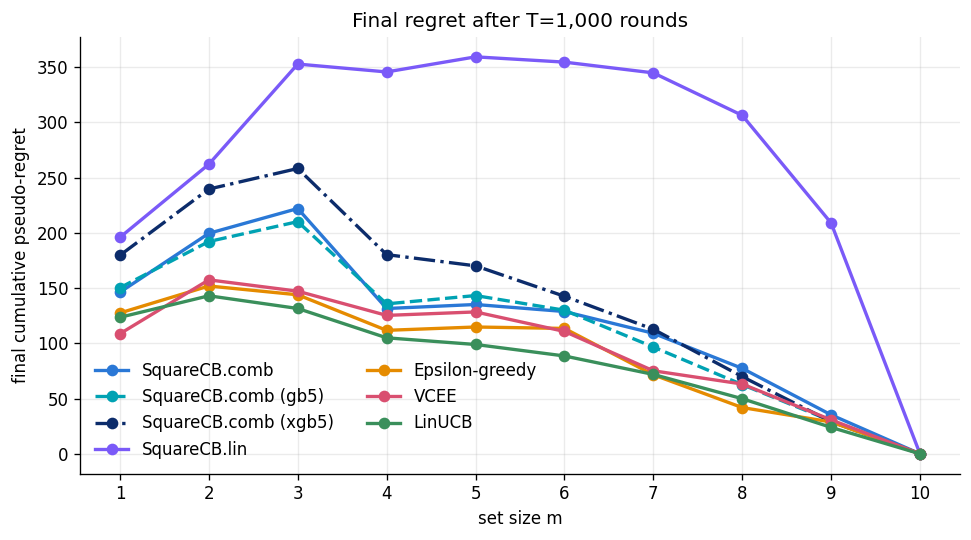

Saved 12 graphs to results/noncontextual_mset/


algorithm,Epsilon-greedy,LinUCB,SquareCB.comb,SquareCB.comb (gb5),SquareCB.comb (xgb5),SquareCB.lin,VCEE
m,,,,,,,
1,127.5,123.6,146.3,150.4,179.7,196.0,108.7
2,151.9,143.1,199.6,192.2,239.7,262.2,157.5
3,144.0,131.6,222.1,210.2,258.3,352.9,147.2
4,111.8,105.0,131.6,135.8,180.3,345.8,125.3
5,114.8,99.0,135.2,143.3,170.2,359.4,128.5
6,113.5,88.6,128.8,130.0,142.6,354.6,110.8
7,71.6,71.9,109.1,96.7,112.8,344.9,75.2
8,41.9,49.9,77.4,62.6,69.9,306.4,63.2
9,28.9,23.9,35.3,29.9,29.1,209.0,30.7


In [6]:
def add_regret_curves(ax, m, compact=False):
    for name in ALGORITHMS:
        reg = np.stack([run["cum_regret"] for run in runs[m][name]])
        mean = reg.mean(axis=0)
        se = (reg.std(axis=0, ddof=1) / np.sqrt(CFG.n_seeds)
              if CFG.n_seeds > 1 else np.zeros(CFG.T))
        ax.plot(steps, mean, lw=1.8, color=colors[name],
                ls=styles[name], label=name)
        ax.fill_between(steps, mean - 1.96 * se, mean + 1.96 * se,
                        color=colors[name], alpha=0.12, lw=0)
    ax.set_title(f"m = {m}  |  C({K},m) = {math.comb(K, m)}", loc="left")
    ax.set_xlabel("" if compact else "round")
    ax.set_ylabel("" if compact else "cumulative pseudo-regret")
    ax.grid(alpha=0.22)


panel_figures(add_regret_curves,
              outdir=CFG.output_dir,
              per_m_name="regret_m_{m:02d}.png",
              grid_name="all_m_regret_grid.png",
              suptitle=f"Non-contextual m-set semi-bandit (K={K})",
              xlabel="round", ylabel="cumulative pseudo-regret",
              legend_ncol=4, legend_y=1.05, suptitle_y=1.12)

rows = []
tail = max(1, CFG.T // 5)
for m in CFG.m_values:
    for name in ALGORITHMS:
        reg = np.stack([run["cum_regret"] for run in runs[m][name]])
        rew = np.stack([run["cum_reward"] for run in runs[m][name]])
        hit = np.stack([run["optimal"] for run in runs[m][name]])
        rows.append({"m": m, "algorithm": name,
                     "final pseudo-regret": reg[:, -1].mean(),
                     "regret sd": reg[:, -1].std(ddof=1),
                     "reward / round": (rew[:, -1] / CFG.T).mean(),
                     "optimal-set rate (last 20%)": hit[:, -tail:].mean()})
summary = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(8.2, 4.6))
for name in ALGORITHMS:
    part = summary[summary.algorithm == name]
    ax.plot(part.m, part["final pseudo-regret"], marker="o", lw=2,
            color=colors[name], ls=styles[name], label=name)
ax.set(xlabel="set size m", ylabel="final cumulative pseudo-regret",
       xticks=CFG.m_values, title=f"Final regret after T={CFG.T:,} rounds")
ax.grid(alpha=0.25)
ax.legend(frameon=False, ncol=2)
save_fig(fig, os.path.join(CFG.output_dir, "final_regret_vs_m.png"))

print(f"Saved {len(CFG.m_values) + 2} graphs to {CFG.output_dir}/")
summary.pivot(index="m", columns="algorithm",
              values="final pseudo-regret").round(1)


## SquareCB multiplier sensitivity

For all four SquareCB variants, the stock schedule is $\gamma_t=c\sqrt{Kt/m}$. We sweep $c=2^e$ for $e=-3,-2.5,\ldots,3$ while holding the reward stream, model, and all other parameters fixed. Curves below report final pseudo-regret after $T$ rounds; bands are 95% normal confidence intervals across seeds. The per-$m$ figures and combined grid are saved under `CFG.output_dir/gamma_sweep`. The sweep matters more for the tree rows than it looks: IGW trades $\langle p,\hat f\rangle$ against $\gamma^{-1}\sum_k\log p_k$, so the *scale* of $\hat f$ sets the effective exploration level, and a tree ensemble that shrinks toward the buffer mean early on presents IGW with a flatter score vector than the linear head does at the same $\gamma$.


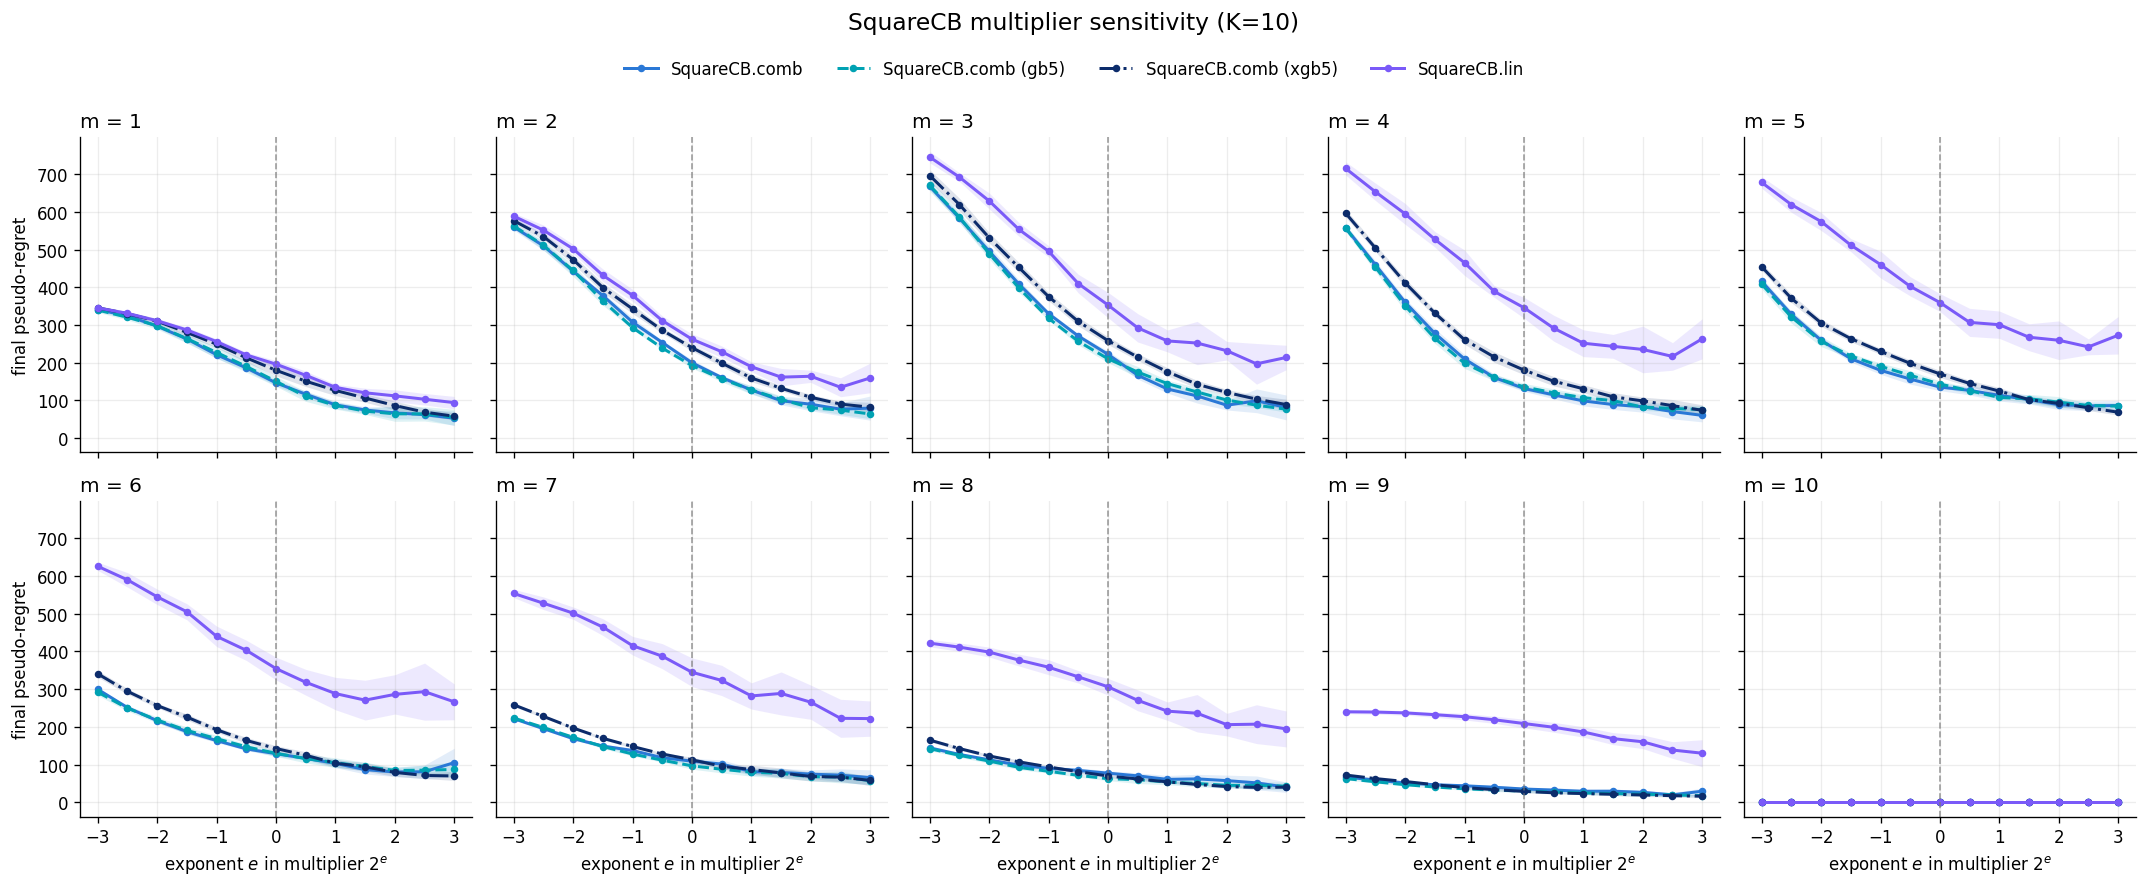

Saved 11 multiplier-sensitivity graphs to results/noncontextual_mset/gamma_sweep/


algorithm,SquareCB.comb,SquareCB.comb (gb5),SquareCB.comb (xgb5),SquareCB.lin
m,,,,
1,2^3 (52.5),2^3 (55.4),2^3 (57.9),2^3 (94.0)
2,2^2.5 (76.6),2^3 (63.9),2^3 (81.9),2^2.5 (134.8)
3,2^3 (81.2),2^3 (76.5),2^3 (88.9),2^2.5 (196.9)
4,2^3 (60.2),2^3 (75.7),2^3 (73.7),2^2.5 (216.5)
5,2^2.5 (85.5),2^3 (84.7),2^3 (68.6),2^2.5 (241.8)
6,2^2 (80.4),2^2 (84.5),2^3 (70.0),2^3 (266.4)
7,2^3 (65.6),2^3 (57.6),2^3 (58.1),2^3 (222.0)
8,2^3 (40.2),2^3 (43.0),2^2.5 (39.7),2^3 (194.7)
9,2^2.5 (19.8),2^3 (17.9),2^3 (16.2),2^3 (130.3)


In [7]:
gamma_rows = []
for m in CFG.m_values:
    for name in SQUARECB_ALGORITHMS:
        for exponent in CFG.gamma_exponents:
            reg = np.stack([run["cum_regret"]
                            for run in gamma_runs[m][name][exponent]])
            gamma_rows.append({"m": m, "algorithm": name,
                               "exponent": exponent,
                               "multiplier": 2.0 ** exponent,
                               "final pseudo-regret": reg[:, -1].mean(),
                               "se": (reg[:, -1].std(ddof=1)
                                      / np.sqrt(CFG.n_seeds))})
gamma_summary = pd.DataFrame(gamma_rows)
gamma_dir = os.path.join(CFG.output_dir, "gamma_sweep")
gamma_ticks = np.arange(math.ceil(min(CFG.gamma_exponents)),
                        math.floor(max(CFG.gamma_exponents)) + 1)


def add_gamma_curves(ax, m, compact=False):
    for name in SQUARECB_ALGORITHMS:
        part = gamma_summary[(gamma_summary.m == m)
                             & (gamma_summary.algorithm == name)]
        x = part.exponent.to_numpy()
        y = part["final pseudo-regret"].to_numpy()
        ci = 1.96 * part.se.to_numpy()
        ax.plot(x, y, marker="o", ms=3.5, lw=1.8,
                color=colors[name], ls=styles[name], label=name)
        ax.fill_between(x, y - ci, y + ci, color=colors[name],
                        alpha=0.13, lw=0)
    ax.axvline(0, color="#777777", ls="--", lw=1, alpha=0.7)
    ax.set_title(f"m = {m}", loc="left")
    ax.set_xticks(gamma_ticks)
    ax.set_xlabel("" if compact else "exponent e")
    ax.set_ylabel("" if compact else "final pseudo-regret")
    ax.grid(alpha=0.22)


panel_figures(add_gamma_curves,
              outdir=gamma_dir,
              per_m_name="gamma_sensitivity_m_{m:02d}.png",
              grid_name="gamma_sensitivity_grid.png",
              suptitle=f"SquareCB multiplier sensitivity (K={K})",
              xlabel=r"exponent $e$ in multiplier $2^e$",
              ylabel="final pseudo-regret",
              legend_ncol=len(SQUARECB_ALGORITHMS),
              annotate=r"$\gamma$ multiplier $=2^e$")

# Break exact ties in favor of the reference exponent e=0.
best = (gamma_summary.assign(abs_exponent=gamma_summary.exponent.abs())
        .sort_values(["m", "algorithm", "final pseudo-regret", "abs_exponent"])
        .groupby(["m", "algorithm"], as_index=False).first())
best["best multiplier (regret)"] = [
    f"2^{e:g} ({r:.1f})" for e, r in
    zip(best.exponent, best["final pseudo-regret"])]
print(f"Saved {len(CFG.m_values) + 1} multiplier-sensitivity graphs to {gamma_dir}/")
best.pivot(index="m", columns="algorithm",
           values="best multiplier (regret)")


### Reading the comparison

This is a realizable, stationary sanity check rather than a comprehensive benchmark. One-hot features deliberately remove representation error, which is exactly the condition under which the two boosted-tree oracles have nothing to gain and a shrinkage cost to pay: read `gb5` and `xgb5` as an upper bound on what a nonparametric oracle costs inside IGW when the linear model is already correct, not as evidence about trees in general. `SquareCB.lin` receives strictly less feedback than the other methods, so its curves should be interpreted with that distinction in mind. The boundary case $m=10$ has only one feasible action and therefore zero pseudo-regret for every method. Change only `CFG` to vary the arm means, swept set sizes, horizon, replications, parallelism, or output folder.
